# Phase 5 scratch: model vs rings at the same review budget
Four ways to choose the same 3,520 test transactions (top 2%) for review:
1. **Baseline model**: transaction + velocity features (Phase 3)
2. **Ring flag alone**: test transactions whose identity sits in a ring scored on training labels (Phase 4)
3. **Model + ring alert**: ring transactions jump the queue, the model fills the rest
4. **Model + network features**: baseline features plus as-of network features, retrained

Network features are computed as of each transaction's date: a link only counts once both identities have shown the shared value, neighbor labels stop at day 120 for test rows (day minus 30 for training rows), and an identity's own labels are never used. Each model is trained with 3 seeds; scores come from `python src/compare.py`.

In [1]:
import sys
sys.path.insert(0, '../../src')
import pandas as pd, compare, model, viz
pd.set_option('display.width', 250)
df = compare.load_frame()
train, test = model.split(df)
scores = pd.read_parquet(compare.RESULTS_PARQUET)
assert (scores.TransactionID.values == test.TransactionID.values).all()
r, missed = compare.compare(test, scores)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## Recall, dollars and precision at the same budget (mean and std over 3 seeds)

In [2]:
r[['fraud_caught', 'recall', 'fraud_amt_caught', 'precision']].round(4)

fraud_caught           recall         fraud_amt_caught            precision        
                                 mean      std    mean     std             mean        std      mean     std
approach                                                                                                    
Baseline model              2571.6667  21.1266  0.4242  0.0035      338557.3557  4428.6240    0.7306  0.0060
Ring flag alone               73.0000   0.0000  0.0120  0.0000        5326.7530     0.0000    0.6404  0.0000
Model + ring alert          2563.6667  23.1157  0.4228  0.0038      334694.9727  6093.6479    0.7283  0.0066
Model + network features    2585.3333   9.2376  0.4264  0.0015      341117.4273   382.8921    0.7345  0.0026

## The brief's headline: of the fraud the baseline missed, how much did the network view catch?
`newly_caught` is the gross number. `baseline_catches_lost` counts fraud the baseline caught that the new approach pushed out of the budget. The net gain is what matters.

In [3]:
missed[['baseline_missed', 'newly_caught', 'pct_of_missed_caught', 'newly_caught_amt', 'baseline_catches_lost', 'net_fraud_gain', 'net_amt_gain']].round(4)

baseline_missed          newly_caught          pct_of_missed_caught         newly_caught_amt            baseline_catches_lost          net_fraud_gain          net_amt_gain           
                                    mean      std         mean      std                 mean     std             mean        std                  mean      std           mean      std         mean        std
approach                                                                                                                                                                                                       
Ring flag alone                3491.3333  21.1266       8.0000   6.0828               0.0023  0.0018         427.2040   272.7022             2506.6667  26.9506     -2498.6667  21.1266 -333230.6027  4428.6240
Model + ring alert             3491.3333  21.1266       8.0000   6.0828               0.0023  0.0018         427.2040   272.7022               16.0000   4.3589        -8.0000   2.0000   -3862.3830  2665.4616
Model + network features       3491.3333  21.1266     120.6667  10.2144               0.0346  0.0031       25364.1857  3105.3270              107.0000  23.3024        13.6667  13.2035    2560.0717  4274.9408

## Why so little gain: the baseline already sees the rings
Share of each fraud segment that the baseline model already flags inside its 2% budget.

In [4]:
cov = compare.coverage(test, scores)
cov.round(3)

,fraud,caught_mean,share,share_min,share_max
segment,,,,,
All test fraud,6063,2571.667,0.424,0.421,0.428
Fraud with a known-fraud neighbor,836,561.000,0.671,0.664,0.683
Fraud inside a ring,73,65.000,0.890,0.795,0.945


PosixPath('figures/05_headline_comparison.png')

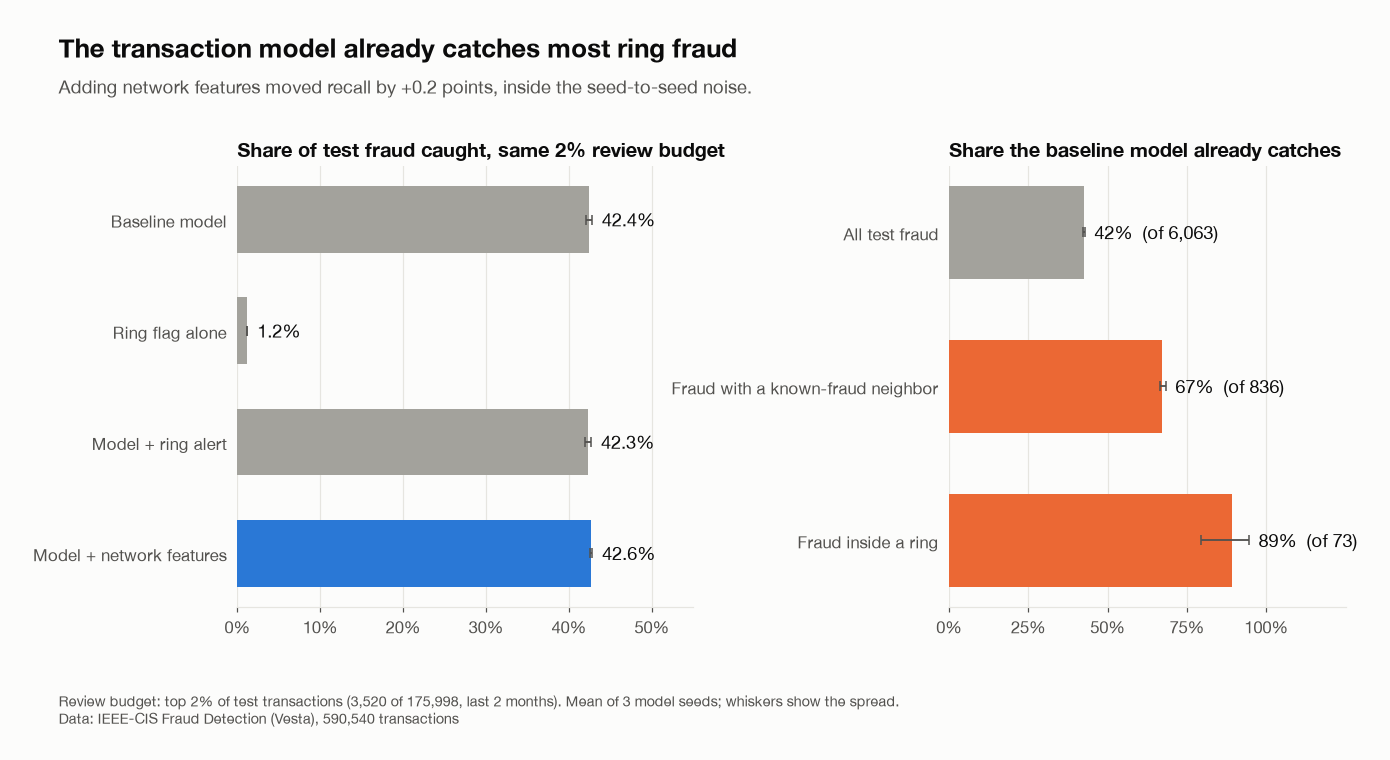

In [5]:
fig = compare.plot_headline(r, cov)
viz.save(fig, '05_headline_comparison')

## Reading
* Network features moved recall from 42.4% to 42.6% (std 0.35 and 0.15 points across seeds). That is inside the noise.
* Gross, they caught about 3.5% of the fraud the baseline missed (about 121 transactions, $25K), but pushed out about 107 baseline catches ($23K). Net: +14 transactions, plus or minus 13.
* Rings are real: ring transactions are 64% fraud against a 3.4% base rate. But the baseline already flags 89% of that fraud, and 67% of fraud with a known-fraud neighbor, against 42% of fraud overall.
* The links (card, device, email) and Vesta's count fields are already model inputs, so the network view mostly re-finds what the model sees.
* Business read: a graph pipeline would add cost and alert volume without catching more fraud here. The rings stay useful for explaining fraud to investigators (case study, hero image), not as a new detector.